Section 1 — Raw EDA         (Cells 1–5: shape, gaps, sentinel, raw correlations)
Section 2 — Build features  (Cell 6: build_features)
Section 3 — Feature EDA     (Cells 7–9: heating overlay, cooling rate)
Section 4 — Feature visuals (Cells A–F: the six plots above)
Section 5 — Save            (Cell 10: to_csv)

Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

Load and Inspect

In [3]:
df = pd.read_csv("../data/thermostat_log.csv", parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nDate range:", df.timestamp.min(), "->", df.timestamp.max())
print("\nMissng values:\n", df.isnull().sum())
print("\nHeating distribution:\n", df["heating"].value_counts(dropna=False))
df.describe

Shape: (7791, 11)

Dtypes:
 timestamp             datetime64[us]
temperature                  float64
target_temperature           float64
heating                         bool
battery                        int64
signal                         int64
online                          bool
outside_temp                 float64
humidity                       int64
wind_speed                   float64
weather_desc                     str
dtype: object

Date range: 2026-09-22 04:06:49.602306 -> 2026-11-06 13:00:05.619530

Missng values:
 timestamp             0
temperature           0
target_temperature    0
heating               0
battery               0
signal                0
online                0
outside_temp          0
humidity              0
wind_speed            0
weather_desc          0
dtype: int64

Heating distribution:
 heating
False    7330
True      461
Name: count, dtype: int64


<bound method NDFrame.describe of                       timestamp  temperature  target_temperature  heating  \
0    2026-09-22 04:06:49.602306         22.3                 6.0    False   
1    2026-09-22 04:15:04.667312         22.3                 6.0    False   
2    2026-09-22 04:20:04.467698         22.2                 6.0    False   
3    2026-09-22 04:21:29.855090         22.2                 6.0    False   
4    2026-09-22 04:25:05.221833         22.2                 6.0    False   
...                         ...          ...                 ...      ...   
7786 2026-11-06 12:40:05.504740         22.4                23.5     True   
7787 2026-11-06 12:45:05.219609         22.4                23.5     True   
7788 2026-11-06 12:50:04.862994         22.4                23.5     True   
7789 2026-11-06 12:55:04.682349         22.5                23.5     True   
7790 2026-11-06 13:00:05.619530         22.5                23.5     True   

      battery  signal  online  outside_te

Data quality

In [4]:
print("Duplicate timestamps:", df.timestamp.duplicated().sum())

deltas = df.timestamp.diff().dt.total_seconds() / 60
print("\nInterval stats (min):\n", deltas.describe())
print("\nGaps > 10 min:\n", deltas[deltas > 10].describe())

print("\nTemp range:", df.temperature.min(), "→", df.temperature.max())
print("Outside temp range:", df.outside_temp.min(), "→", df.outside_temp.max())
print("\nTarget values:", sorted(df.target_temperature.unique()))

Duplicate timestamps: 0

Interval stats (min):
 count     7790.000000
mean         8.386812
std        236.954652
min          1.423123
25%          4.995535
50%          4.997691
75%          5.005485
max      20125.010731
Name: timestamp, dtype: float64

Gaps > 10 min:
 count       51.000000
mean       516.869549
std       2912.244267
min         10.000051
25%         10.001810
50%         10.004677
75%         10.014759
max      20125.010731
Name: timestamp, dtype: float64

Temp range: 17.8 → 25.4
Outside temp range: 6.08 → 26.75

Target values: [np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(20.0), np.float64(20.5), np.float64(21.0), np.float64(22.0), np.float64(23.5), np.float64(24.0), np.float64(25.0)]


Time series plot

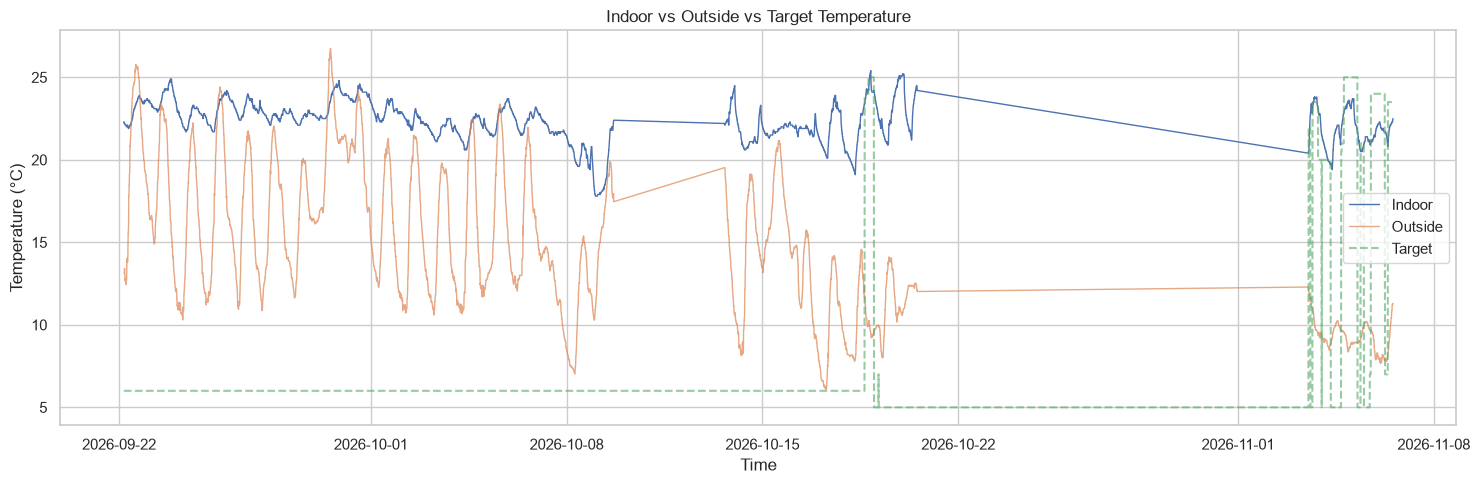

In [5]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.timestamp, df.temperature, label="Indoor", lw=1)
ax.plot(df.timestamp, df.outside_temp, label="Outside", alpha=0.7, lw=1)
ax.plot(df.timestamp, df.target_temperature, label="Target", ls="--", alpha=0.6)
ax.set_xlabel("Time"); ax.set_ylabel("Temperature (°C)")
ax.set_title("Indoor vs Outside vs Target Temperature")
ax.legend(); plt.tight_layout(); plt.show()

Daily and weekly patterns

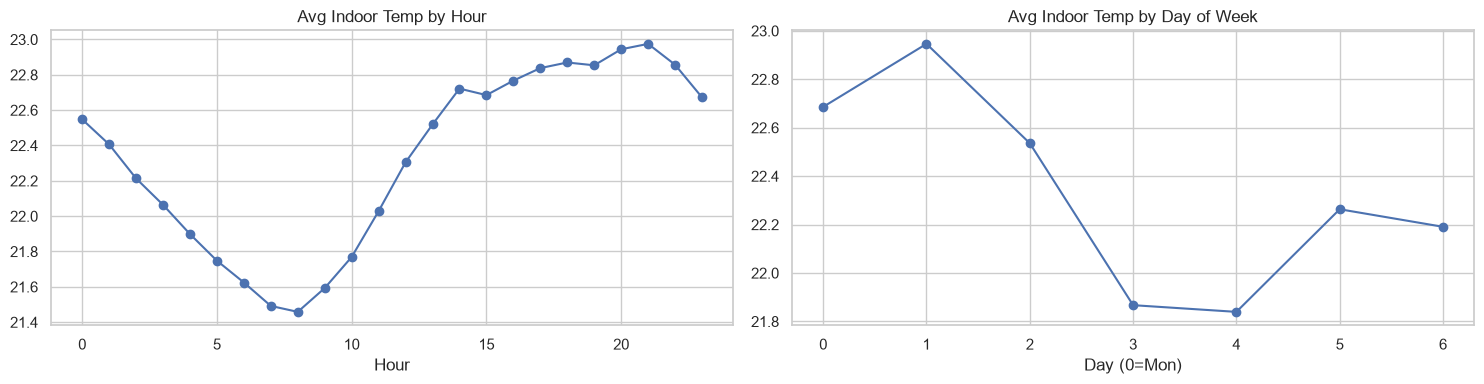

In [6]:
df["hour"] = df.timestamp.dt.hour
df["day_of_week"] = df.timestamp.dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df.groupby("hour")["temperature"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Avg Indoor Temp by Hour"); axes[0].set_xlabel("Hour")

df.groupby("day_of_week")["temperature"].mean().plot(ax=axes[1], marker="o")
axes[1].set_title("Avg Indoor Temp by Day of Week"); axes[1].set_xlabel("Day (0=Mon)")
plt.tight_layout(); plt.show()

Correlations

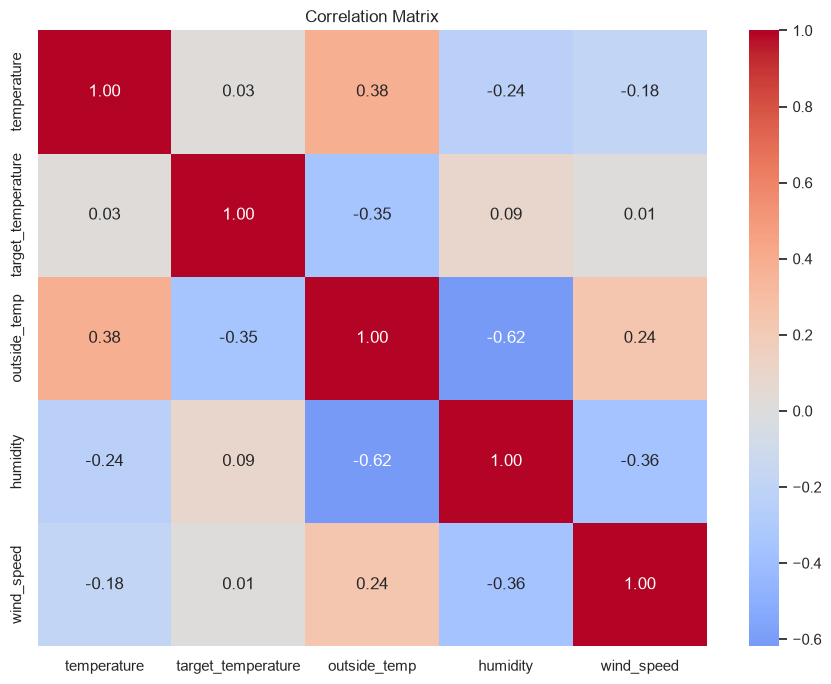

In [7]:
num_cols = ["temperature", "target_temperature", "outside_temp",
            "humidity", "wind_speed"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix"); plt.tight_layout(); plt.show()

Physics metrics: HDD and cooling rate

In [8]:
BASE_TEMP = 15.5  # °C, UK standard for HDD
df["hdd"] = (BASE_TEMP - df.outside_temp).clip(lower=0)

# Cooling rate: dT_indoor/dt vs (T_indoor - T_outside), heating off everywhere
df["dt_indoor"] = df.temperature.diff()          # change per 5-min step
df["delta"] = df.temperature - df.outside_temp   # driving force
cool = df.dropna(subset=["dt_indoor", "delta"])

# μ ≈ -slope of dT/dt against (T_in - T_out); fit through origin
slope = np.polyfit(cool["delta"], cool["dt_indoor"], 1)[0]
mu = -slope * 12  # convert per-5-min to per-hour
print(f"Cooling rate μ ≈ {mu:.3f} per hour (fraction of ΔT lost per hour)")
print(f"Equivalent time constant τ ≈ {1/mu:.1f} hours")

Cooling rate μ ≈ 0.019 per hour (fraction of ΔT lost per hour)
Equivalent time constant τ ≈ 52.0 hours


Exploring engineered features

In [9]:
import sys; sys.path.append("..")
from src.features import build_features, FEATURE_COLS, TARGET_COL

feat = build_features(df)
print("Feature rows:", len(feat))
print("Segments:", feat.segment.value_counts().to_dict())
print("Heating on:", feat.heating_on.sum(), "rows")
print("Nulls in features:", feat[FEATURE_COLS].isnull().sum().sum())

# Correlations of engineered features with the target
corr = feat[FEATURE_COLS + [TARGET_COL]].corr()[TARGET_COL].sort_values(ascending=False)
print("\nCorrelation with temperature:\n", corr.drop(TARGET_COL).round(3))

Feature rows: 7719
Segments: {1: 4966, 2: 1919, 3: 834}
Heating on: 451 rows
Nulls in features: 0

Correlation with temperature:
 temperature_lag_1           0.999
temperature_roll_mean_3     0.998
temperature_lag_3           0.996
temperature_roll_mean_12    0.989
temperature_roll_mean_24    0.970
temperature_lag_12          0.966
temperature_lag_24          0.903
outside_temp                0.382
dow_cos                     0.264
dow_sin                     0.150
hour_cos                    0.103
setpoint_active             0.011
heating_on                  0.004
temperature_roll_std_12    -0.017
temp_diff                  -0.117
wind_speed                 -0.179
humidity                   -0.241
hdd                        -0.323
hour_sin                   -0.389
month                      -0.412
Name: temperature, dtype: float64


In [11]:
# Filter to Autumn (segments 1 and 2) and Heating OFF
cool = feat[(feat["segment"].isin([1, 2])) & (feat["heating_on"] == 0)].copy()

# Calculate the change per 5-min step
cool["dt_indoor"] = cool["temperature"].diff()

# Drop the NaN created by .diff() and the segment boundaries
cool = cool.dropna(subset=["dt_indoor", "temp_diff"])

# Fit through origin (polyfit with degree 1)
slope = np.polyfit(cool["temp_diff"], cool["dt_indoor"], 1)[0]
mu = -slope * 12  # convert per-5-min to per-hour

print(f"Fitted on {len(cool)} cooling-off rows")
print(f"Cooling rate μ ≈ {mu:.4f} per hour")
print(f"Equivalent time constant τ ≈ {1/mu:.1f} hours")

# Print HDD stats
print(f"\nHDD stats:\n{df['hdd'].describe().round(2)}")

Fitted on 6827 cooling-off rows
Cooling rate μ ≈ 0.0236 per hour
Equivalent time constant τ ≈ 42.4 hours

HDD stats:
count    7791.00
mean        2.38
std         2.60
min         0.00
25%         0.00
50%         1.49
75%         4.41
max         9.42
Name: hdd, dtype: float64


Setup for segment plots

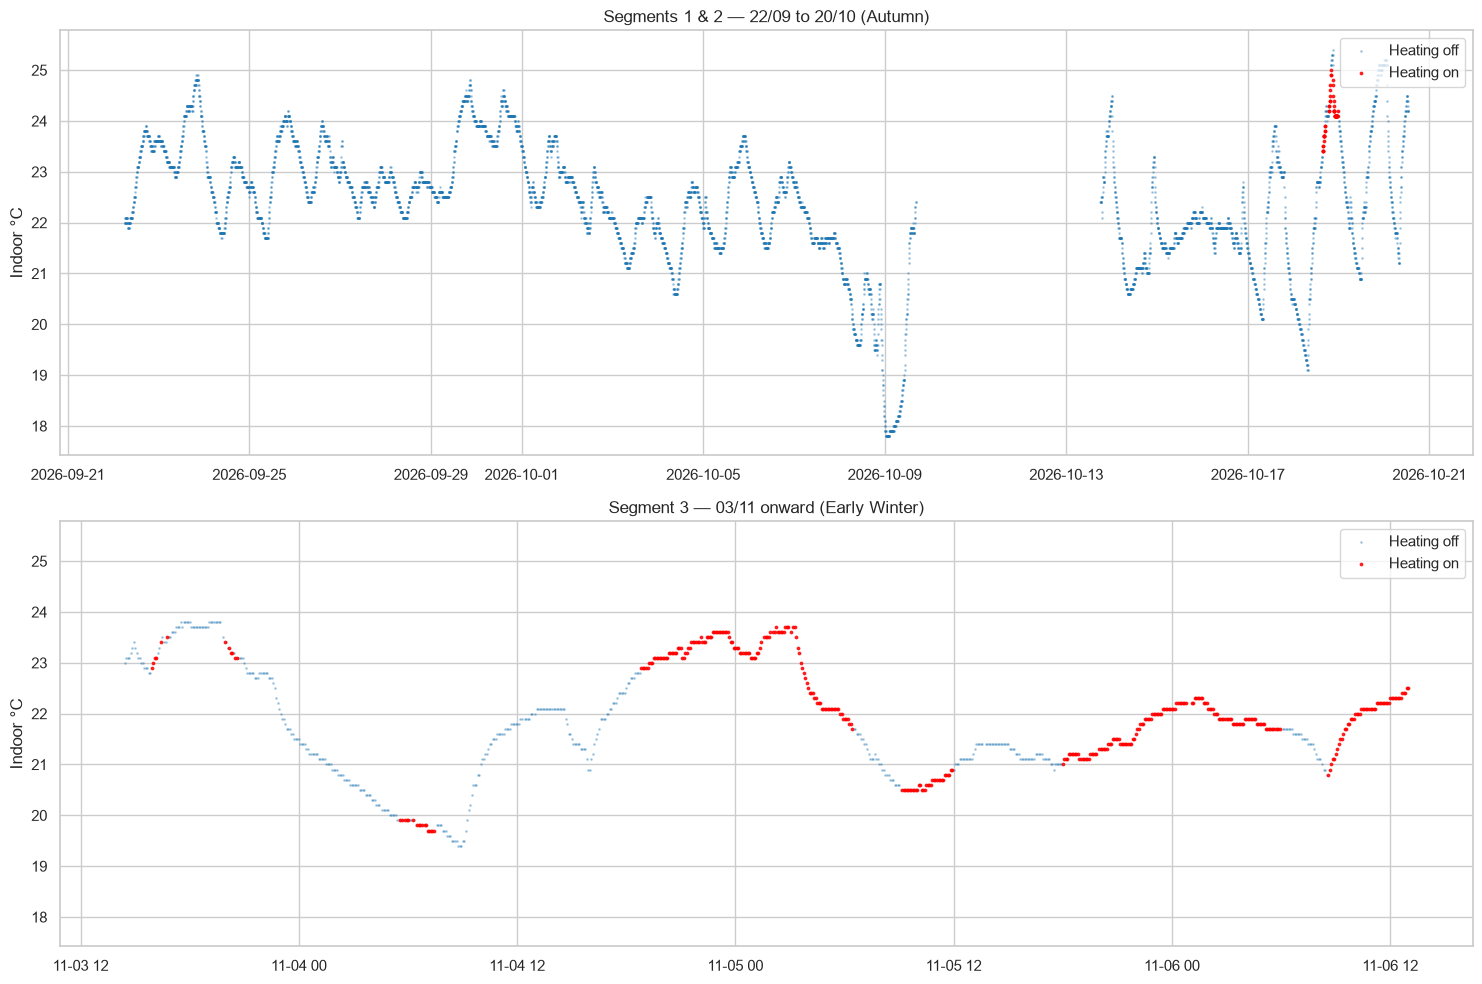

In [13]:
# Split by segment for gap-free plotting
# Segments 1 and 2 are Autumn (with the 4-day gap between them)
autumn = feat[feat.segment.isin([1, 2])].copy()
# Segment 3 is Early Winter (after the 14-day gap)
winter = feat[feat.segment == 3].copy()

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharey=True)

for ax, seg, title in [(axes[0], autumn, "Segments 1 & 2 — 22/09 to 20/10 (Autumn)"),
                       (axes[1], winter, "Segment 3 — 03/11 onward (Early Winter)")]:
    no_heat = seg[seg.heating_on == 0]
    heat    = seg[seg.heating_on == 1]
    
    ax.scatter(no_heat.timestamp, no_heat.temperature, s=1, alpha=0.3, label="Heating off", color="tab:blue")
    ax.scatter(heat.timestamp, heat.temperature, s=3, alpha=0.8, label="Heating on", color="red")
    
    ax.set_title(title)
    ax.set_ylabel("Indoor °C")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

Daily Cycle (Heating On vs. Off)

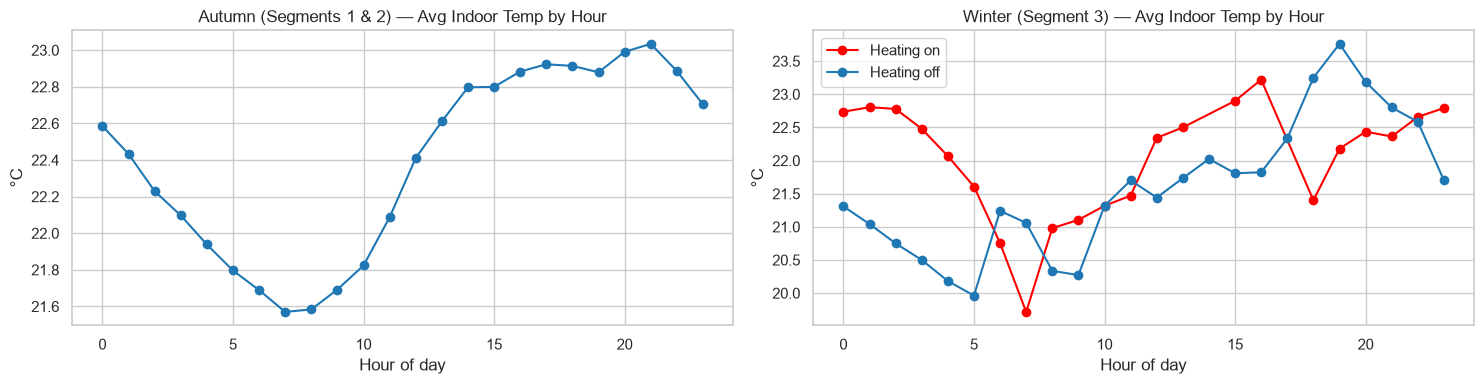

In [14]:
# Define the segments locally for these plots
autumn = feat[feat.segment.isin([1, 2])]
winter = feat[feat.segment == 3]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Autumn (mostly heating off)
autumn.groupby("hour")["temperature"].mean().plot(ax=axes[0], marker="o", color="tab:blue")
axes[0].set_title("Autumn (Segments 1 & 2) — Avg Indoor Temp by Hour")
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("°C")

# Winter (heating on vs off)
hourly_on  = winter[winter.heating_on == 1].groupby("hour")["temperature"].mean()
hourly_off = winter[winter.heating_on == 0].groupby("hour")["temperature"].mean()

axes[1].plot(hourly_on.index,  hourly_on.values,  marker="o", label="Heating on",  color="red")
axes[1].plot(hourly_off.index, hourly_off.values, marker="o", label="Heating off", color="tab:blue")
axes[1].set_title("Winter (Segment 3) — Avg Indoor Temp by Hour")
axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("°C")
axes[1].legend()

plt.tight_layout(); plt.show()

Weekly Pattern

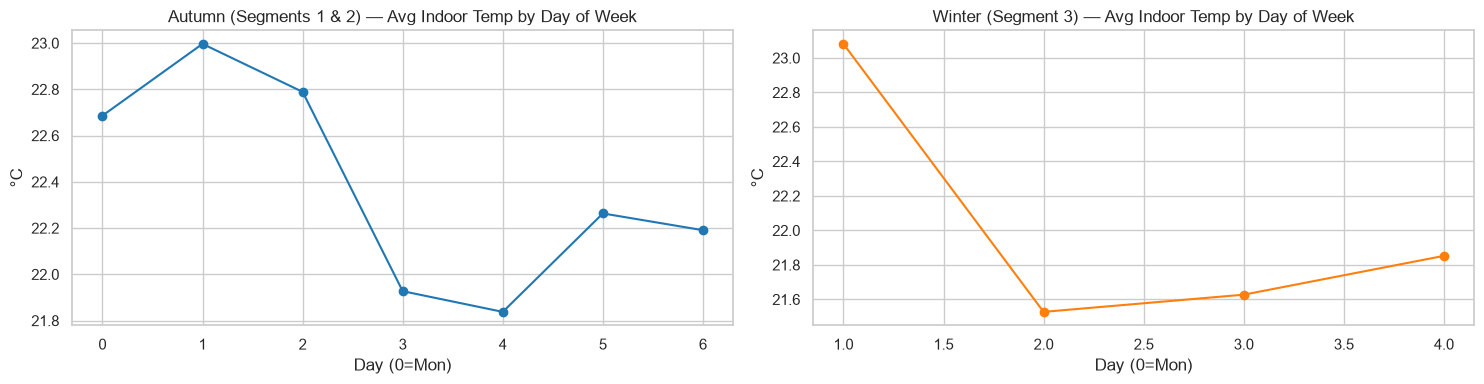

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

autumn.groupby("day_of_week")["temperature"].mean().plot(ax=axes[0], marker="o", color="tab:blue")
axes[0].set_title("Autumn (Segments 1 & 2) — Avg Indoor Temp by Day of Week")
axes[0].set_xlabel("Day (0=Mon)"); axes[0].set_ylabel("°C")

winter.groupby("day_of_week")["temperature"].mean().plot(ax=axes[1], marker="o", color="tab:orange")
axes[1].set_title("Winter (Segment 3) — Avg Indoor Temp by Day of Week")
axes[1].set_xlabel("Day (0=Mon)"); axes[1].set_ylabel("°C")

plt.tight_layout(); plt.show()

HDD vs Indoor Temperature

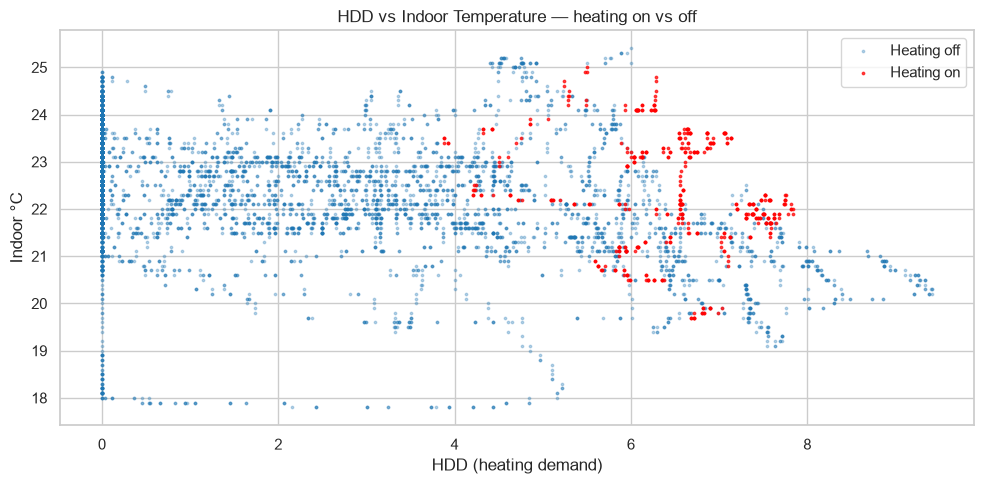

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
no_heat = feat[feat.heating_on == 0]
heat    = feat[feat.heating_on == 1]

ax.scatter(no_heat.hdd, no_heat.temperature, s=3, alpha=0.3, label="Heating off", color="tab:blue")
ax.scatter(heat.hdd,    heat.temperature,    s=3, alpha=0.7, label="Heating on", color="red")

ax.set_xlabel("HDD (heating demand)"); ax.set_ylabel("Indoor °C")
ax.set_title("HDD vs Indoor Temperature — heating on vs off")
ax.legend(); plt.tight_layout(); plt.show()

Cooling Curve Scatter

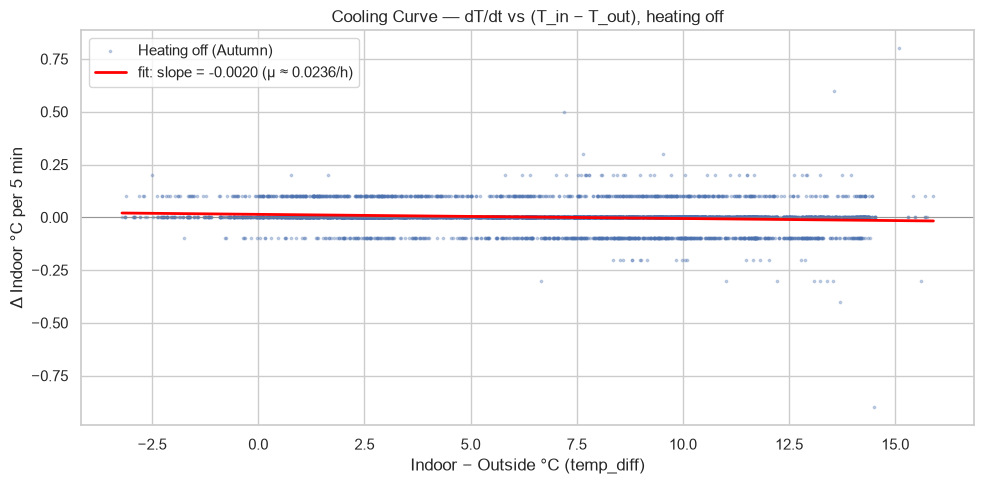

In [17]:
# Filter to Autumn (Segments 1 & 2) and Heating OFF
cool = feat[feat.segment.isin([1, 2]) & (feat.heating_on == 0)].copy()

# Calculate the change per 5-min step
cool["dt_indoor"] = cool["temperature"].diff()
plot_data = cool.dropna(subset=["dt_indoor", "temp_diff"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(plot_data.temp_diff, plot_data.dt_indoor, s=3, alpha=0.3, label="Heating off (Autumn)")
ax.axhline(0, color="grey", lw=0.5)

# Overlay the fitted line
slope, intercept = np.polyfit(plot_data.temp_diff, plot_data.dt_indoor, 1)
x_vals = np.linspace(plot_data.temp_diff.min(), plot_data.temp_diff.max(), 100)
ax.plot(x_vals, slope * x_vals + intercept, color="red", lw=2,
        label=f"fit: slope = {slope:.4f} (μ ≈ {-slope*12:.4f}/h)")

ax.set_xlabel("Indoor − Outside °C (temp_diff)")
ax.set_ylabel("Δ Indoor °C per 5 min")
ax.set_title("Cooling Curve — dT/dt vs (T_in − T_out), heating off")
ax.legend(); plt.tight_layout(); plt.show()

Lag 1 vs. Indoor Temperature

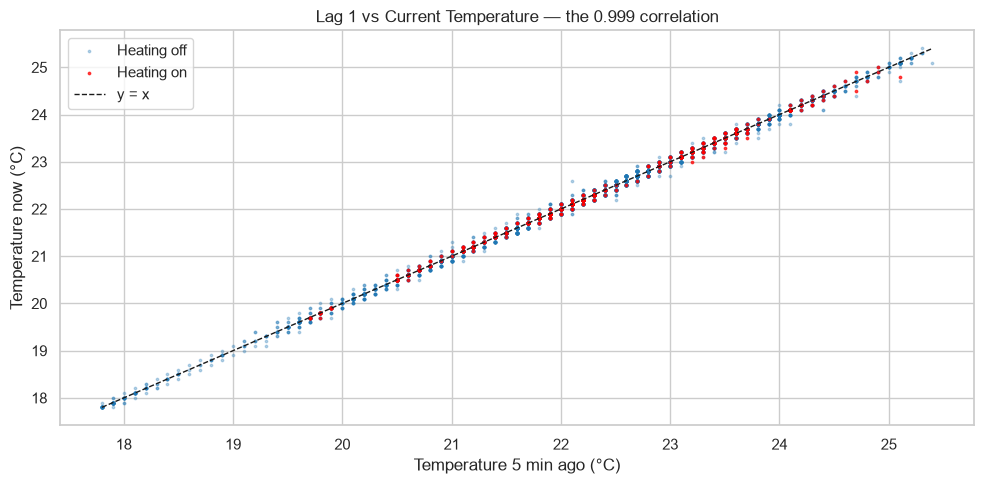

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
no_heat = feat[feat.heating_on == 0]
heat    = feat[feat.heating_on == 1]

ax.scatter(no_heat.temperature_lag_1, no_heat.temperature, s=3, alpha=0.3, label="Heating off", color="tab:blue")
ax.scatter(heat.temperature_lag_1,    heat.temperature,    s=3, alpha=0.7, label="Heating on", color="red")

# y = x reference line
lims = [feat.temperature_lag_1.min(), feat.temperature_lag_1.max()]
ax.plot(lims, lims, "k--", lw=1, label="y = x")

ax.set_xlabel("Temperature 5 min ago (°C)")
ax.set_ylabel("Temperature now (°C)")
ax.set_title("Lag 1 vs Current Temperature — the 0.999 correlation")
ax.legend(); plt.tight_layout(); plt.show()

Save

In [19]:
feat.to_csv("../data/thermostat_features.csv", index=False)
print("Saved:", feat.shape)

Saved: (7719, 35)
